In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [2]:
data = pd.read_csv('Diabetes_Prediction_Dataset.csv')

In [3]:
data.head()

,Patient_ID,Age,Gender,BMI,Glucose,Blood_Pressure,Cholesterol,Insulin,HbA1c,Smoking_Status,Physical_Activity,Family_History,Diabetes
0,1,58,Male,17.6,140.0,121,177,86,9.7,Current,High,Yes,Yes
1,2,56,Male,31.0,209.0,143,176,244,8.6,Never,Low,No,Yes
2,3,23,Female,19.4,158.0,167,187,37,9.6,Current,Low,No,No
3,4,41,Male,34.6,81.0,174,178,163,11.4,Never,Low,No,No
4,5,31,Female,34.5,88.0,167,282,102,8.2,Never,Low,No,No


In [4]:
data.tail()

,Patient_ID,Age,Gender,BMI,Glucose,Blood_Pressure,Cholesterol,Insulin,HbA1c,Smoking_Status,Physical_Activity,Family_History,Diabetes
4995,4996,66,Male,38.0,115.0,94,146,291,7.8,Former,Moderate,Yes,Yes
4996,4997,34,Male,39.3,164.0,118,281,16,11.3,Never,Low,No,Yes
4997,4998,29,Male,41.3,174.0,172,316,92,8.0,Former,Moderate,No,Yes
4998,4999,45,Female,23.5,73.0,148,136,236,5.5,Current,Low,No,No
4999,5000,62,Female,40.6,183.0,142,290,278,5.4,Never,Low,Yes,Yes


In [5]:
data.sample(5)

,Patient_ID,Age,Gender,BMI,Glucose,Blood_Pressure,Cholesterol,Insulin,HbA1c,Smoking_Status,Physical_Activity,Family_History,Diabetes
850,851,80,Male,22.5,115.0,120,214,200,6.9,Never,High,No,No
3115,3116,74,Male,26.3,73.0,143,301,147,10.5,Former,Moderate,Yes,Yes
4425,4426,18,Female,32.7,92.0,101,124,271,4.8,Current,Low,No,No
4741,4742,79,Male,23.5,148.0,120,315,149,6.5,Current,High,Yes,Yes
385,386,73,Female,25.2,175.0,157,173,122,8.8,Never,High,Yes,Yes


In [6]:
data.shape

(5000, 13)

In [7]:
data.columns

Index(['Patient_ID', 'Age', 'Gender', 'BMI', 'Glucose', 'Blood_Pressure',
       'Cholesterol', 'Insulin', 'HbA1c', 'Smoking_Status',
       'Physical_Activity', 'Family_History', 'Diabetes'],
      dtype='str')

In [8]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Patient_ID         5000 non-null   int64  
 1   Age                5000 non-null   int64  
 2   Gender             5000 non-null   str    
 3   BMI                4893 non-null   float64
 4   Glucose            4930 non-null   float64
 5   Blood_Pressure     5000 non-null   int64  
 6   Cholesterol        5000 non-null   int64  
 7   Insulin            5000 non-null   int64  
 8   HbA1c              5000 non-null   float64
 9   Smoking_Status     5000 non-null   str    
 10  Physical_Activity  5000 non-null   str    
 11  Family_History     5000 non-null   str    
 12  Diabetes           5000 non-null   str    
dtypes: float64(3), int64(5), str(5)
memory usage: 611.4 KB


In [9]:
data.describe()

,Patient_ID,Age,BMI,Glucose,Blood_Pressure,Cholesterol,Insulin,HbA1c
count,5000.000000,5000.000000,4893.000000,4930.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,2500.500000,48.986400,29.407398,144.456795,143.139200,221.426800,157.746200,7.988300
std,1443.520003,18.173813,7.254359,43.887777,87.414816,57.436379,82.357275,2.017408
min,1.000000,18.000000,17.000000,70.000000,90.000000,120.000000,15.000000,4.500000
25%,1250.750000,33.000000,23.100000,106.000000,112.000000,172.000000,86.000000,6.200000
50%,2500.500000,49.000000,29.400000,144.000000,136.000000,222.000000,158.000000,7.900000
75%,3750.250000,65.000000,35.800000,182.000000,158.000000,271.000000,229.000000,9.800000
max,5000.000000,80.000000,42.000000,220.000000,999.000000,320.000000,300.000000,11.500000


In [10]:
data.describe(include='object')

,Gender,Smoking_Status,Physical_Activity,Family_History,Diabetes
count,5000,5000,5000,5000,5000
unique,3,3,3,2,2
top,Female,Former,Moderate,No,Yes
freq,2525,1711,1734,2507,2988


In [11]:
data.isnull().sum()

Patient_ID             0
Age                    0
Gender                 0
BMI                  107
Glucose               70
Blood_Pressure         0
Cholesterol            0
Insulin                0
HbA1c                  0
Smoking_Status         0
Physical_Activity      0
Family_History         0
Diabetes               0
dtype: int64

In [12]:
(data.isnull().sum() / len(data)) * 100

Patient_ID           0.00
Age                  0.00
Gender               0.00
BMI                  2.14
Glucose              1.40
Blood_Pressure       0.00
Cholesterol          0.00
Insulin              0.00
HbA1c                0.00
Smoking_Status       0.00
Physical_Activity    0.00
Family_History       0.00
Diabetes             0.00
dtype: float64

In [13]:
data.duplicated().sum()

np.int64(0)

In [14]:
data.dtypes

Patient_ID             int64
Age                    int64
Gender                   str
BMI                  float64
Glucose              float64
Blood_Pressure         int64
Cholesterol            int64
Insulin                int64
HbA1c                float64
Smoking_Status           str
Physical_Activity        str
Family_History           str
Diabetes                 str
dtype: object

In [15]:
for column in data.columns:
    print(column, ':', data[column].nunique())

Patient_ID : 5000
Age : 63
Gender : 3
BMI : 251
Glucose : 151
Blood_Pressure : 92
Cholesterol : 201
Insulin : 286
HbA1c : 71
Smoking_Status : 3
Physical_Activity : 3
Family_History : 2
Diabetes : 2


In [16]:
data = data.drop_duplicates()

In [17]:
data.shape

(5000, 13)

In [18]:
data.isnull().sum()

Patient_ID             0
Age                    0
Gender                 0
BMI                  107
Glucose               70
Blood_Pressure         0
Cholesterol            0
Insulin                0
HbA1c                  0
Smoking_Status         0
Physical_Activity      0
Family_History         0
Diabetes               0
dtype: int64

In [19]:
data['BMI'] = data['BMI'].fillna(data['BMI'].median())

data['Glucose'] = data['Glucose'].fillna(data['Glucose'].median())

In [20]:
data.isnull().sum()

Patient_ID           0
Age                  0
Gender               0
BMI                  0
Glucose              0
Blood_Pressure       0
Cholesterol          0
Insulin              0
HbA1c                0
Smoking_Status       0
Physical_Activity    0
Family_History       0
Diabetes             0
dtype: int64

In [21]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Patient_ID         5000 non-null   int64  
 1   Age                5000 non-null   int64  
 2   Gender             5000 non-null   str    
 3   BMI                5000 non-null   float64
 4   Glucose            5000 non-null   float64
 5   Blood_Pressure     5000 non-null   int64  
 6   Cholesterol        5000 non-null   int64  
 7   Insulin            5000 non-null   int64  
 8   HbA1c              5000 non-null   float64
 9   Smoking_Status     5000 non-null   str    
 10  Physical_Activity  5000 non-null   str    
 11  Family_History     5000 non-null   str    
 12  Diabetes           5000 non-null   str    
dtypes: float64(3), int64(5), str(5)
memory usage: 611.4 KB


In [22]:
nc = data.select_dtypes(include=['int64', 'float64']).columns
nc

Index(['Patient_ID', 'Age', 'BMI', 'Glucose', 'Blood_Pressure', 'Cholesterol',
       'Insulin', 'HbA1c'],
      dtype='str')

In [23]:
data[nc].describe()

,Patient_ID,Age,BMI,Glucose,Blood_Pressure,Cholesterol,Insulin,HbA1c
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,2500.500000,48.986400,29.407240,144.450400,143.139200,221.426800,157.746200,7.988300
std,1443.520003,18.173813,7.176302,43.579451,87.414816,57.436379,82.357275,2.017408
min,1.000000,18.000000,17.000000,70.000000,90.000000,120.000000,15.000000,4.500000
25%,1250.750000,33.000000,23.200000,106.000000,112.000000,172.000000,86.000000,6.200000
50%,2500.500000,49.000000,29.400000,144.000000,136.000000,222.000000,158.000000,7.900000
75%,3750.250000,65.000000,35.600000,182.000000,158.000000,271.000000,229.000000,9.800000
max,5000.000000,80.000000,42.000000,220.000000,999.000000,320.000000,300.000000,11.500000


In [24]:
import seaborn as sns

data.columns

Index(['Patient_ID', 'Age', 'Gender', 'BMI', 'Glucose', 'Blood_Pressure',
       'Cholesterol', 'Insulin', 'HbA1c', 'Smoking_Status',
       'Physical_Activity', 'Family_History', 'Diabetes'],
      dtype='str')

<Axes: xlabel='BMI'>

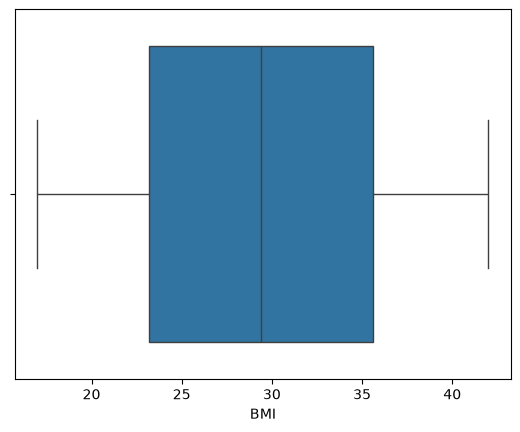

In [25]:
sns.boxplot(data['BMI'], orient="h")

<Axes: xlabel='Glucose'>

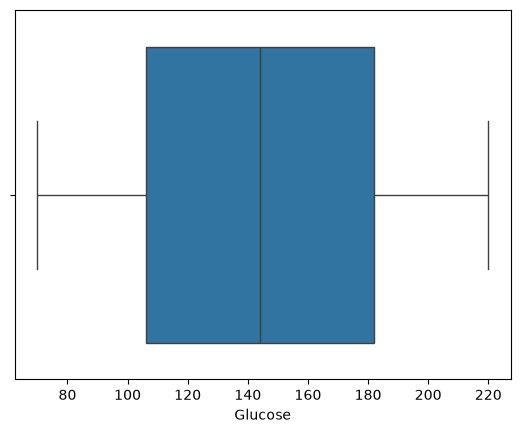

In [26]:
sns.boxplot(data['Glucose'], orient="h")

In [27]:
sorted(data['BMI'], reverse=True)[:10]

[42.0, 42.0, 42.0, 42.0, 42.0, 42.0, 42.0, 42.0, 41.9, 41.9]

In [28]:
sorted(data['Glucose'], reverse=True)[:10]

[220.0, 220.0, 220.0, 220.0, 220.0, 220.0, 220.0, 220.0, 220.0, 220.0]

In [29]:
data.columns

Index(['Patient_ID', 'Age', 'Gender', 'BMI', 'Glucose', 'Blood_Pressure',
       'Cholesterol', 'Insulin', 'HbA1c', 'Smoking_Status',
       'Physical_Activity', 'Family_History', 'Diabetes'],
      dtype='str')

In [30]:
data.head()

,Patient_ID,Age,Gender,BMI,Glucose,Blood_Pressure,Cholesterol,Insulin,HbA1c,Smoking_Status,Physical_Activity,Family_History,Diabetes
0,1,58,Male,17.6,140.0,121,177,86,9.7,Current,High,Yes,Yes
1,2,56,Male,31.0,209.0,143,176,244,8.6,Never,Low,No,Yes
2,3,23,Female,19.4,158.0,167,187,37,9.6,Current,Low,No,No
3,4,41,Male,34.6,81.0,174,178,163,11.4,Never,Low,No,No
4,5,31,Female,34.5,88.0,167,282,102,8.2,Never,Low,No,No


In [31]:
data['Gender'].unique()

<ArrowStringArray>
['Male', 'Female', 'Unknown']
Length: 3, dtype: str

In [32]:
data['Smoking_Status'].unique()

<ArrowStringArray>
['Current', 'Never', 'Former']
Length: 3, dtype: str

In [33]:
data['Physical_Activity'].unique()

<ArrowStringArray>
['High', 'Low', 'Moderate']
Length: 3, dtype: str

In [34]:
data['Physical_Activity'].unique()

<ArrowStringArray>
['High', 'Low', 'Moderate']
Length: 3, dtype: str

In [35]:
data['Family_History'].unique()

<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str

In [36]:
data['Diabetes'].unique()

<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str

In [37]:
data['Gender'] = data['Gender'].map({'Male':0, 'Female':1, 'Unknown':2})

In [38]:
data['Smoking_Status'] = data['Smoking_Status'].map({'Current':0, 'Never':1, 'Former':2})

In [39]:
data['Physical_Activity'] = data['Physical_Activity'].map({'High':0, 'Low':1, 'Moderate':2})

In [40]:
data['Family_History'] = data['Family_History'].map({'No':0, 'Yes':1})

In [41]:
data['Diabetes'] = data['Diabetes'].map({'No':0, 'Yes':1})

In [42]:
data.head()

,Patient_ID,Age,Gender,BMI,Glucose,Blood_Pressure,Cholesterol,Insulin,HbA1c,Smoking_Status,Physical_Activity,Family_History,Diabetes
0,1,58,0,17.6,140.0,121,177,86,9.7,0,0,1,1
1,2,56,0,31.0,209.0,143,176,244,8.6,1,1,0,1
2,3,23,1,19.4,158.0,167,187,37,9.6,0,1,0,0
3,4,41,0,34.6,81.0,174,178,163,11.4,1,1,0,0
4,5,31,1,34.5,88.0,167,282,102,8.2,1,1,0,0


In [43]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Patient_ID         5000 non-null   int64  
 1   Age                5000 non-null   int64  
 2   Gender             5000 non-null   int64  
 3   BMI                5000 non-null   float64
 4   Glucose            5000 non-null   float64
 5   Blood_Pressure     5000 non-null   int64  
 6   Cholesterol        5000 non-null   int64  
 7   Insulin            5000 non-null   int64  
 8   HbA1c              5000 non-null   float64
 9   Smoking_Status     5000 non-null   int64  
 10  Physical_Activity  5000 non-null   int64  
 11  Family_History     5000 non-null   int64  
 12  Diabetes           5000 non-null   int64  
dtypes: float64(3), int64(10)
memory usage: 507.9 KB


In [44]:
X = data.drop(['Patient_ID', 'Diabetes'], axis=1)
y = data['Diabetes']

In [45]:
X.head()

,Age,Gender,BMI,Glucose,Blood_Pressure,Cholesterol,Insulin,HbA1c,Smoking_Status,Physical_Activity,Family_History
0,58,0,17.6,140.0,121,177,86,9.7,0,0,1
1,56,0,31.0,209.0,143,176,244,8.6,1,1,0
2,23,1,19.4,158.0,167,187,37,9.6,0,1,0
3,41,0,34.6,81.0,174,178,163,11.4,1,1,0
4,31,1,34.5,88.0,167,282,102,8.2,1,1,0


In [46]:
y.head()

0    1
1    1
2    0
3    0
4    0
Name: Diabetes, dtype: int64

In [47]:
from sklearn.model_selection import train_test_split

In [48]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

In [49]:
X_test.head()

,Age,Gender,BMI,Glucose,Blood_Pressure,Cholesterol,Insulin,HbA1c,Smoking_Status,Physical_Activity,Family_History
1092,40,0,25.8,169.0,114,259,143,9.6,0,1,1
1643,59,1,23.6,72.0,169,259,76,4.6,1,0,1
2555,34,1,27.5,193.0,99,213,151,5.3,2,0,0
78,68,1,23.1,102.0,162,172,50,10.3,0,1,1
1172,25,0,22.5,89.0,175,259,166,6.6,0,1,1


In [50]:
y_test

1092    1
1643    0
2555    0
78      1
1172    0
       ..
2482    1
2082    1
1531    1
4861    1
1214    0
Name: Diabetes, Length: 1000, dtype: int64

In [51]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

In [52]:
DT = DecisionTreeClassifier(random_state=42)
RF = RandomForestClassifier(random_state=42)
GB = GradientBoostingClassifier(random_state=42)

In [53]:
DT.fit(X_train, y_train)
RF.fit(X_train, y_train)
GB.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

In [54]:
DT_Pred = DT.predict(X_test)

In [55]:
RF_Pred = RF.predict(X_test)

In [56]:
GB_Pred = GB.predict(X_test)

In [57]:
from sklearn import metrics

In [58]:
DT_Accuracy = metrics.accuracy_score(y_test, DT_Pred)
RF_Accuracy = metrics.accuracy_score(y_test, RF_Pred)
GB_Accuracy = metrics.accuracy_score(y_test, GB_Pred)

In [59]:
DT_F1 = metrics.f1_score(y_test, DT_Pred)
RF_F1 = metrics.f1_score(y_test, RF_Pred)
GB_F1 = metrics.f1_score(y_test, GB_Pred)

In [60]:
DT_Recall = metrics.recall_score(y_test, DT_Pred)
RF_Recall = metrics.recall_score(y_test, RF_Pred)
GB_Recall = metrics.recall_score(y_test, GB_Pred)

In [61]:
final_data = pd.DataFrame({
    'Models': ['Decision Tree', 'Random Forest', 'Gradient Boosting'],
    'Accuracy': [DT_Accuracy, RF_Accuracy, GB_Accuracy],
    'F1 Score': [DT_F1, RF_F1, GB_F1],
    'Recall': [DT_Recall, RF_Recall, GB_Recall]
})

In [62]:
final_data

,Models,Accuracy,F1 Score,Recall
0,Decision Tree,0.988,0.989967,0.989967
1,Random Forest,0.994,0.994992,0.996656
2,Gradient Boosting,0.993,0.994152,0.994983


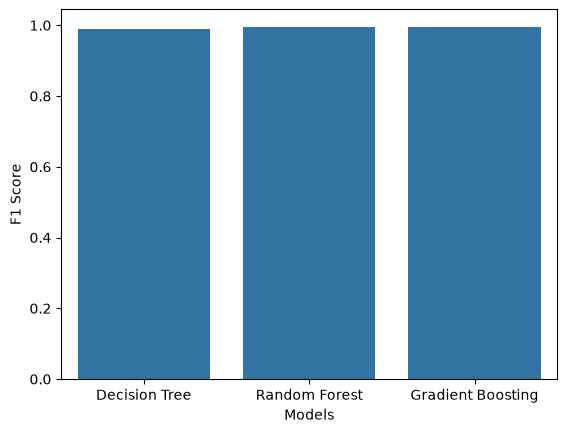

In [63]:
sns.barplot(x=final_data['Models'], y=final_data['F1 Score'])
plt.show()

In [64]:
from sklearn.metrics import confusion_matrix, classification_report

In [65]:
confusion_matrix(y_test, RF_Pred)

array([[398,   4],
       [  2, 596]])

In [66]:
print(classification_report(y_test, RF_Pred))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       402
           1       0.99      1.00      0.99       598

    accuracy                           0.99      1000
   macro avg       0.99      0.99      0.99      1000
weighted avg       0.99      0.99      0.99      1000



In [67]:
RF.fit(X, y)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [68]:
import joblib

In [69]:
joblib.dump(RF, 'diabetes_prediction_model.pkl')

['diabetes_prediction_model.pkl']

In [70]:
model = joblib.load('diabetes_prediction_model.pkl')

In [71]:
model

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr